### Import required libraries :

In [1]:
# Step 2: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Machine Learning
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


### Load training and testing datasets :

In [2]:
# Step 3: Load Train-Test Datasets

PROJECT_DIR = Path(
    r"C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics"
)

def find_file(filename):
    matches = list(PROJECT_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"{filename} was not found."
        )

    return matches[0]

# Locate files
X_train_path = find_file("X_train.csv")
X_test_path = find_file("X_test.csv")
y_train_path = find_file("y_train.csv")
y_test_path = find_file("y_test.csv")

# Load datasets
X_train = pd.read_csv(X_train_path)
X_test = pd.read_csv(X_test_path)

y_train = pd.read_csv(y_train_path).squeeze("columns")
y_test = pd.read_csv(y_test_path).squeeze("columns")

# Reset indexes to ensure alignment
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Datasets loaded successfully.")

print("\nTraining Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Datasets loaded successfully.

Training Data:
X_train: (70577, 50)
y_train: (70577,)

Testing Data:
X_test: (56642, 50)
y_test: (56642,)


### Check target distribution :

In [3]:
# Step 4: Check Target Distribution

print("Training Target Distribution:")
display(y_train.value_counts())

print("\nTesting Target Distribution:")
display(y_test.value_counts())

print("\nTraining Adoption Rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting Adoption Rate:")
print(round(y_test.mean() * 100, 2), "%")

Training Target Distribution:


feature_adopted
0    68957
1     1620
Name: count, dtype: int64


Testing Target Distribution:


feature_adopted
0    56269
1      373
Name: count, dtype: int64


Training Adoption Rate:
2.3 %

Testing Adoption Rate:
0.66 %


### Identify numerical and categorical features :

In [5]:
# Step 5: Identify Numerical and Categorical Features

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Number of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

assert len(numerical_features) + len(categorical_features) == X_train.shape[1]
assert len(set(numerical_features) & set(categorical_features)) == 0

print("\nFeature classification validated.")

Number of Numerical Features: 43
Number of Categorical Features: 7

Numerical Features:
['is_verified', 'total_event_count', 'active_event_days', 'unique_sessions', 'unique_event_types', 'unique_platforms', 'unique_device_types', 'analytics_dashboard_viewed', 'api_key_created', 'documentation_viewed', 'first_api_request', 'login', 'sdk_integrated', 'signup', 'subscription_upgraded', 'webhook_created', 'api_total_requests', 'api_success_count', 'api_error_count', 'api_avg_response_time_ms', 'api_max_response_time_ms', 'api_unique_endpoints', 'api_success_rate', 'api_error_rate', 'api_requests_analytics', 'api_requests_auth', 'api_requests_orders', 'api_requests_products', 'api_requests_users', 'api_requests_webhooks', 'api_has_activity', 'signup_tenure_days', 'user_is_admin', 'organization_tenure_days', 'subscription_monthly_price', 'subscription_started', 'subscription_tenure_days', 'has_adopted_api_authentication', 'has_adopted_api_documentation', 'has_adopted_analytics_dashboard', 'h

### Check missing values :

In [6]:
# Step 6: Check Missing Values

print("Categorical Missing Values:")
display(X_train[categorical_features].isna().sum())

print("\nNumerical Missing Values:")
display(X_train[numerical_features].isna().sum())

print("\nTotal Missing Values:", X_train.isna().sum().sum())

Categorical Missing Values:


country                         0
user_role                       0
acquisition_channel             0
organization_industry           0
organization_company_size       0
organization_country            0
subscription_plan_type       4989
dtype: int64


Numerical Missing Values:


is_verified                           0
total_event_count                     0
active_event_days                     0
unique_sessions                       0
unique_event_types                    0
unique_platforms                      0
unique_device_types                   0
analytics_dashboard_viewed            0
api_key_created                       0
documentation_viewed                  0
first_api_request                     0
login                                 0
sdk_integrated                        0
signup                                0
subscription_upgraded                 0
webhook_created                       0
api_total_requests                    0
api_success_count                     0
api_error_count                       0
api_avg_response_time_ms              0
api_max_response_time_ms              0
api_unique_endpoints                  0
api_success_rate                      0
api_error_rate                        0
api_requests_analytics                0



Total Missing Values: 14967


### Build the numerical preprocessing pipeline :

In [7]:
# Step 7: Numerical Preprocessing Pipeline

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


### Build the categorical preprocessing pipeline :

In [8]:
# Step 8: Categorical Preprocessing Pipeline

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Not Started"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


### Combine both preprocessing pipelines :

In [9]:
# Step 9: Combine Numerical and Categorical Pipelines

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Complete preprocessing pipeline created.")

Complete preprocessing pipeline created.


### Build the Dummy Classifier :

In [10]:
# Step 10: Train Dummy Classifier

dummy_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(strategy="most_frequent")
        )
    ]
)

# Train using training data only
dummy_model.fit(X_train, y_train)

print("Dummy Classifier trained successfully.")

Dummy Classifier trained successfully.


### Generate predictions :

In [11]:
# Step 11: Generate Dummy Classifier Predictions

y_pred_dummy = dummy_model.predict(X_test)

print("Predictions generated successfully.")

print("\nFirst 20 Predictions:")
print(y_pred_dummy[:20])

print("\nPredicted Class Distribution:")
display(pd.Series(y_pred_dummy).value_counts())

Predictions generated successfully.

First 20 Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Predicted Class Distribution:


0    56642
Name: count, dtype: int64

### Evaluate Dummy Classifier :

In [12]:
# Step 12: Evaluate Dummy Classifier

dummy_accuracy = accuracy_score(
    y_test,
    y_pred_dummy
)

dummy_precision = precision_score(
    y_test,
    y_pred_dummy,
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    y_pred_dummy,
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    y_pred_dummy,
    zero_division=0
)

dummy_roc_auc = roc_auc_score(
    y_test,
    dummy_model.predict_proba(X_test)[:, 1]
)

dummy_pr_auc = average_precision_score(
    y_test,
    dummy_model.predict_proba(X_test)[:, 1]
)

print("Dummy Classifier Performance")
print("----------------------------")
print("Accuracy:", round(dummy_accuracy, 4))
print("Precision:", round(dummy_precision, 4))
print("Recall:", round(dummy_recall, 4))
print("F1-Score:", round(dummy_f1, 4))
print("ROC-AUC:", round(dummy_roc_auc, 4))
print("PR-AUC:", round(dummy_pr_auc, 4))

Dummy Classifier Performance
----------------------------
Accuracy: 0.9934
Precision: 0.0
Recall: 0.0
F1-Score: 0.0
ROC-AUC: 0.5
PR-AUC: 0.0066


### Generate the confusion matrix :

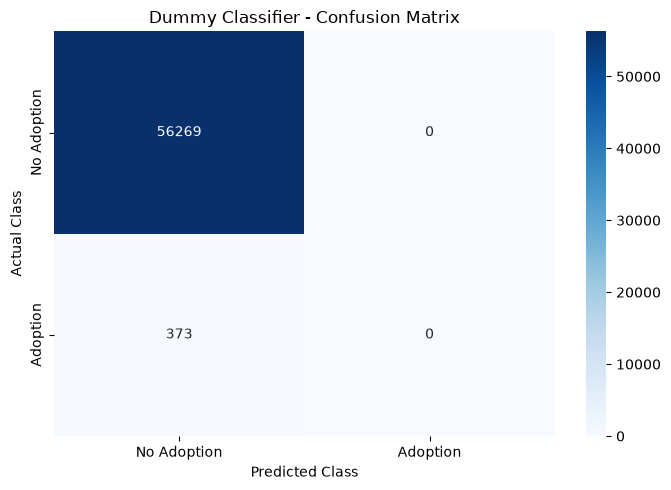

In [13]:
# Step 13: Dummy Classifier Confusion Matrix

dummy_cm = confusion_matrix(
    y_test,
    y_pred_dummy
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    dummy_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Adoption", "Adoption"],
    yticklabels=["No Adoption", "Adoption"]
)

plt.title("Dummy Classifier - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

### Save Dummy Classifier results :

In [14]:
# Step 14: Save Dummy Classifier Results

dummy_results = pd.DataFrame([{
    "Model": "Dummy Classifier",
    "Accuracy": dummy_accuracy,
    "Precision": dummy_precision,
    "Recall": dummy_recall,
    "F1_Score": dummy_f1,
    "ROC_AUC": dummy_roc_auc,
    "PR_AUC": dummy_pr_auc
}])

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dummy_results.to_csv(
    OUTPUT_DIR / "dummy_classifier_results.csv",
    index=False
)

display(dummy_results.round(4))

print("\nDummy Classifier results saved successfully.")

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Dummy Classifier,0.9934,0.0,0.0,0.0,0.5,0.0066



Dummy Classifier results saved successfully.


### Build Logistic Regression :

In [15]:
# Step 15: Train Logistic Regression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### Generate predictions :

In [16]:
# Step 16: Generate Logistic Regression Predictions

y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 20 Predicted Classes:")
print(y_pred_logistic[:20])

print("\nFirst 20 Adoption Probabilities:")
print(np.round(y_prob_logistic[:20], 4))

print("\nPredicted Class Distribution:")
display(pd.Series(y_pred_logistic).value_counts())

Predictions generated successfully.

First 20 Predicted Classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Adoption Probabilities:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted Class Distribution:


0    51910
1     4732
Name: count, dtype: int64

### Inspect prediction probabilities :

In [17]:
# Step 17: Analyze Logistic Regression Probabilities

print("Probability Summary:")
display(
    pd.Series(y_prob_logistic).describe().round(8)
)

print("\nMinimum Probability:")
print(y_prob_logistic.min())

print("\nMaximum Probability:")
print(y_prob_logistic.max())

print("\nFirst 20 Probabilities (8 decimals):")
print(np.round(y_prob_logistic[:20], 8))

print(
    "\nProbabilities Between 0 and 0.5:",
    ((y_prob_logistic >= 0) & (y_prob_logistic < 0.5)).sum()
)

print(
    "Probabilities Greater Than or Equal to 0.5:",
    (y_prob_logistic >= 0.5).sum()
)

Probability Summary:


count    5.664200e+04
mean     9.922128e-02
std      2.117923e-01
min      2.000000e-08
25%      4.907000e-05
50%      1.911340e-03
75%      5.486983e-02
max      9.630870e-01
dtype: float64


Minimum Probability:
2.007168562853639e-08

Maximum Probability:
0.9630869552159632

First 20 Probabilities (8 decimals):
[3.17e-06 3.75e-06 2.06e-06 4.99e-06 2.85e-06 8.37e-06 3.33e-06 5.86e-06
 3.87e-06 2.60e-06 6.94e-06 3.93e-06 4.98e-06 3.65e-06 4.82e-06 4.50e-06
 2.97e-06 9.66e-06 7.21e-06 6.57e-06]

Probabilities Between 0 and 0.5: 51910
Probabilities Greater Than or Equal to 0.5: 4732


### Evaluate Logistic Regression :

In [18]:
# Step 18: Evaluate Logistic Regression

logistic_accuracy = accuracy_score(
    y_test, y_pred_logistic
)

logistic_precision = precision_score(
    y_test, y_pred_logistic,
    zero_division=0
)

logistic_recall = recall_score(
    y_test, y_pred_logistic,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test, y_pred_logistic,
    zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_test, y_prob_logistic
)

logistic_pr_auc = average_precision_score(
    y_test, y_prob_logistic
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1-Score:", round(logistic_f1, 4))
print("ROC-AUC:", round(logistic_roc_auc, 4))
print("PR-AUC:", round(logistic_pr_auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy: 0.9209
Precision: 0.0659
Recall: 0.8365
F1-Score: 0.1222
ROC-AUC: 0.9516
PR-AUC: 0.0639


### Generate the confusion matrix :

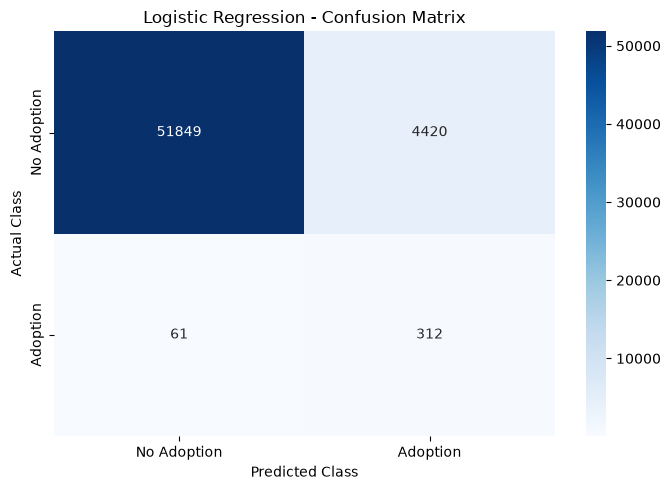

In [19]:
# Step 19: Logistic Regression Confusion Matrix

logistic_cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Adoption", "Adoption"],
    yticklabels=["No Adoption", "Adoption"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

### Inspect the confusion matrix :

In [20]:
print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

tn, fp, fn, tp = logistic_cm.ravel()

print("\nDetailed Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Logistic Regression Confusion Matrix:
[[51849  4420]
 [   61   312]]

Detailed Results:
True Negatives: 51849
False Positives: 4420
False Negatives: 61
True Positives: 312


### Train Decision Tree Classifier :

In [21]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=10,
            min_samples_split=50,
            min_samples_leaf=20,
            random_state=42
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### Generate Decision Tree predictions :

In [26]:
# : Generate Decision Tree Predictions

y_pred_tree = decision_tree_model.predict(X_test)

y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree predictions generated successfully.")

print("\nPredicted Class Distribution:")
print(pd.Series(y_pred_tree).value_counts().sort_index())

print("\nFirst 20 Predicted Classes:")
print(y_pred_tree[:20])

print("\nFirst 20 Adoption Probabilities:")
print(np.round(y_prob_tree[:20], 6))

Decision Tree predictions generated successfully.

Predicted Class Distribution:
0    51416
1     5226
Name: count, dtype: int64

First 20 Predicted Classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Adoption Probabilities:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


### Evaluate Decision Tree performance :

In [25]:
# Step : Evaluate Decision Tree

tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test, y_pred_tree, zero_division=0
)

tree_recall = recall_score(
    y_test, y_pred_tree, zero_division=0
)

tree_f1 = f1_score(
    y_test, y_pred_tree, zero_division=0
)

tree_roc_auc = roc_auc_score(
    y_test, y_prob_tree
)

tree_pr_auc = average_precision_score(
    y_test, y_prob_tree
)

print("Decision Tree Performance")
print("--------------------------")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1-Score:", round(tree_f1, 4))
print("ROC-AUC:", round(tree_roc_auc, 4))
print("PR-AUC:", round(tree_pr_auc, 4))

Decision Tree Performance
--------------------------
Accuracy: 0.9128
Precision: 0.0633
Recall: 0.8874
F1-Score: 0.1182
ROC-AUC: 0.9076
PR-AUC: 0.0699


### Generate Decision Tree confusion matrix :

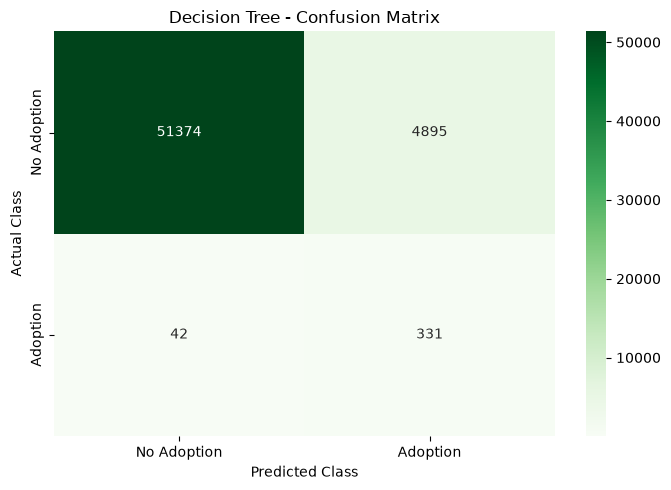

Decision Tree Confusion Matrix:
[[51374  4895]
 [   42   331]]

Detailed Results:
True Negatives: 51374
False Positives: 4895
False Negatives: 42
True Positives: 331


In [24]:
#  Decision Tree Confusion Matrix

tree_cm = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(7, 5))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Adoption", "Adoption"],
    yticklabels=["No Adoption", "Adoption"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Decision Tree Confusion Matrix:")
print(tree_cm)

tn, fp, fn, tp = tree_cm.ravel()

print("\nDetailed Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

### Train Random Forest Classifier :

In [27]:
# Train Random Forest Classifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=50,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### Generate Random Forest predictions :

In [28]:
#  Generate Random Forest Predictions

y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully.")

print("\nPredicted Class Distribution:")
print(pd.Series(y_pred_rf).value_counts().sort_index())

print("\nFirst 20 Predicted Classes:")
print(y_pred_rf[:20])

print("\nFirst 20 Adoption Probabilities:")
print(np.round(y_prob_rf[:20], 6))

Random Forest predictions generated successfully.

Predicted Class Distribution:
0    52357
1     4285
Name: count, dtype: int64

First 20 Predicted Classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Adoption Probabilities:
[0.002487 0.006123 0.       0.000675 0.000524 0.002653 0.000608 0.002073
 0.000324 0.       0.001534 0.002312 0.006424 0.00146  0.000251 0.00056
 0.001687 0.001703 0.000402 0.001229]


### Evaluate Random Forest performance :

In [29]:
#  Evaluate Random Forest

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test, y_prob_rf
)

rf_pr_auc = average_precision_score(
    y_test, y_prob_rf
)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))
print("PR-AUC:", round(rf_pr_auc, 4))

Random Forest Performance
-------------------------
Accuracy: 0.9277
Precision: 0.0656
Recall: 0.7534
F1-Score: 0.1207
ROC-AUC: 0.9547
PR-AUC: 0.0722


### Generate Random Forest confusion matrix :

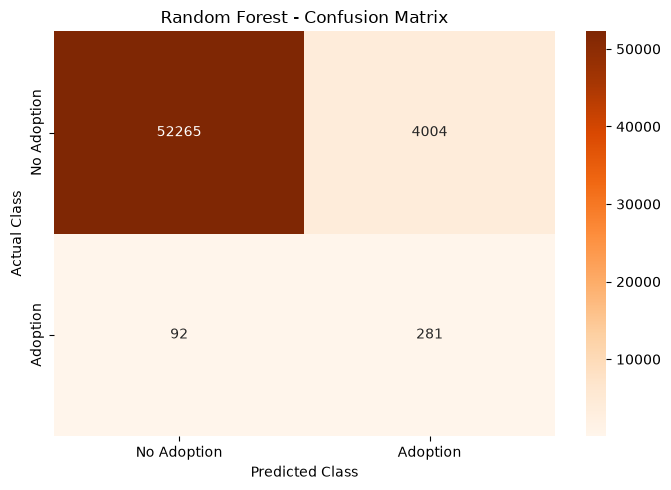

Random Forest Confusion Matrix:
[[52265  4004]
 [   92   281]]

Detailed Results:
True Negatives: 52265
False Positives: 4004
False Negatives: 92
True Positives: 281


In [30]:
# Step 36: Random Forest Confusion Matrix

rf_cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Adoption", "Adoption"],
    yticklabels=["No Adoption", "Adoption"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Random Forest Confusion Matrix:")
print(rf_cm)

tn, fp, fn, tp = rf_cm.ravel()

print("\nDetailed Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

### Create the baseline model comparison table :

In [31]:
# Step 38: Baseline Model Comparison

baseline_results = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": dummy_accuracy,
        "Precision": dummy_precision,
        "Recall": dummy_recall,
        "F1_Score": dummy_f1,
        "ROC_AUC": dummy_roc_auc,
        "PR_AUC": dummy_pr_auc
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1_Score": logistic_f1,
        "ROC_AUC": logistic_roc_auc,
        "PR_AUC": logistic_pr_auc
    },
    {
        "Model": "Decision Tree",
        "Accuracy": tree_accuracy,
        "Precision": tree_precision,
        "Recall": tree_recall,
        "F1_Score": tree_f1,
        "ROC_AUC": tree_roc_auc,
        "PR_AUC": tree_pr_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1_Score": rf_f1,
        "ROC_AUC": rf_roc_auc,
        "PR_AUC": rf_pr_auc
    }
])

display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Dummy Classifier,0.9934,0.0000,0.0000,0.0000,0.5000,0.0066
1,Logistic Regression,0.9209,0.0659,0.8365,0.1222,0.9516,0.0639
2,Decision Tree,0.9128,0.0633,0.8874,0.1182,0.9076,0.0699
3,Random Forest,0.9277,0.0656,0.7534,0.1207,0.9547,0.0722


### Display the comparison table correctly :

In [32]:
# Clean Baseline Comparison Table

baseline_results = baseline_results.reset_index(drop=True)

display(
    baseline_results.round(4)
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Dummy Classifier,0.9934,0.0000,0.0000,0.0000,0.5000,0.0066
1,Logistic Regression,0.9209,0.0659,0.8365,0.1222,0.9516,0.0639
2,Decision Tree,0.9128,0.0633,0.8874,0.1182,0.9076,0.0699
3,Random Forest,0.9277,0.0656,0.7534,0.1207,0.9547,0.0722


### Save baseline model results :

In [33]:
# Save Baseline Model Comparison

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_model_comparison.csv",
    index=False
)

print("Baseline model comparison saved successfully.")
print("File:", OUTPUT_DIR / "baseline_model_comparison.csv")

Baseline model comparison saved successfully.
File: ..\data\processed\baseline_model_comparison.csv


### Save individual model results :

In [34]:
# Save Individual Model Results

individual_results = {
    "dummy_classifier_results.csv": dummy_results,
    "logistic_regression_results.csv": baseline_results[
        baseline_results["Model"] == "Logistic Regression"
    ],
    "decision_tree_results.csv": baseline_results[
        baseline_results["Model"] == "Decision Tree"
    ],
    "random_forest_results.csv": baseline_results[
        baseline_results["Model"] == "Random Forest"
    ]
}

for filename, results in individual_results.items():
    results.to_csv(OUTPUT_DIR / filename, index=False)
    print(f"Saved: {filename}")

Saved: dummy_classifier_results.csv
Saved: logistic_regression_results.csv
Saved: decision_tree_results.csv
Saved: random_forest_results.csv


### Verify saved files :

In [35]:
# Step Verify Saved Baseline Results

required_files = [
    "baseline_model_comparison.csv",
    "dummy_classifier_results.csv",
    "logistic_regression_results.csv",
    "decision_tree_results.csv",
    "random_forest_results.csv"
]

for filename in required_files:
    file_path = OUTPUT_DIR / filename

    print(
        f"{filename}:",
        "Exists" if file_path.exists() else "Missing"
    )

baseline_model_comparison.csv: Exists
dummy_classifier_results.csv: Exists
logistic_regression_results.csv: Exists
decision_tree_results.csv: Exists
random_forest_results.csv: Exists


### Save trained baseline models :

In [36]:
# Step Save Trained Baseline Models

import joblib

MODEL_DIR = Path("../models/baseline")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

models = {
    "dummy_classifier.joblib": dummy_model,
    "logistic_regression.joblib": logistic_model,
    "decision_tree.joblib": decision_tree_model,
    "random_forest.joblib": random_forest_model
}

for filename, model in models.items():
    joblib.dump(model, MODEL_DIR / filename)
    print(f"Saved: {filename}")

Saved: dummy_classifier.joblib
Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: random_forest.joblib


### Final validation of saved models :

In [37]:
# Step Validate Saved Baseline Models

import joblib

for filename in models.keys():
    model_path = MODEL_DIR / filename

    if model_path.exists():
        loaded_model = joblib.load(model_path)
        print(f"{filename}: Loaded successfully")
    else:
        print(f"{filename}: Missing")

dummy_classifier.joblib: Loaded successfully
logistic_regression.joblib: Loaded successfully
decision_tree.joblib: Loaded successfully
random_forest.joblib: Loaded successfully


### Validate model predictions :

In [38]:
# Step Validate Saved Random Forest

loaded_rf = joblib.load(
    MODEL_DIR / "random_forest.joblib"
)

test_predictions = loaded_rf.predict(X_test)

print("Saved model prediction validation")

print("Prediction count:", len(test_predictions))
print("Prediction shape:", test_predictions.shape)
print("Predictions match original:",
      np.array_equal(test_predictions, y_pred_rf))

Saved model prediction validation
Prediction count: 56642
Prediction shape: (56642,)
Predictions match original: True
